In [1]:
from matplotlib.ticker import MaxNLocator
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors
import matplotlib.lines as mlines
import matplotlib.pyplot as plt
from pathlib import Path
import seaborn as sns
import pandas as pd
import numpy as np
import torch
import glob
import math
import sys

rc = {
    "axes.axisbelow": True,
    "axes.linewidth": 1.0,
    "axes.labelsize": "x-small",
    "axes.titlesize": "x-small",
    "figure.dpi": 150,
    "figure.figsize": (3.2, 3.2),
    "font.size": 12.0,
    "legend.fontsize": "xx-small",
    "lines.linewidth": 1.0,
    "savefig.transparent": True,
    "xtick.labelsize": "xx-small",
    "xtick.major.width": 1.0,
    "ytick.labelsize": "xx-small",
    "ytick.major.width": 1.0,
    "font.family": ["serif"],
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amsfonts}",
}

plt.rcParams.update(rc)

PROJECT_ROOT = "/Users/gabrieleaccarino/Workspace/waveletflux"
sys.path.insert(0, PROJECT_ROOT)

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

In [2]:
def rgb_to_hex(r, g, b):
    return f"#{r:02x}{g:02x}{b:02x}"

# ─────────────────────────────────────────────────────────────────────────────
# Palette philosophy
#   · Hue   → wavelet family  (haar=blue, db2=teal, db4=amber, db6=violet)
#   · Value → number of scales (3-scale=deep/saturated, 1-scale=light/muted)
#   · Dash  → 3-scale solid, 1-scale dashed
# ─────────────────────────────────────────────────────────────────────────────

# ── Haar (blue family) ────────────────────────────────────────────────────────
_haar_3  = rgb_to_hex( 42, 100, 185)   # deep cornflower
_haar_1  = rgb_to_hex(143, 191, 232)   # sky mist

# ── db2 (teal-green family) ───────────────────────────────────────────────────
_db2_3   = rgb_to_hex( 34, 148,  97)   # forest teal
_db2_1   = rgb_to_hex(128, 202, 162)   # sage mist

# ── db4 (amber-orange family) ─────────────────────────────────────────────────
_db4_3   = rgb_to_hex(196,  90,  17)   # deep amber
_db4_1   = rgb_to_hex(242, 172, 110)   # peach mist

# ── db6 (violet family) ───────────────────────────────────────────────────────
_db6_3   = rgb_to_hex(118,  50, 160)   # deep amethyst
_db6_1   = rgb_to_hex(195, 153, 220)   # lavender mist

# ── Baseline (neutral) ────────────────────────────────────────────────────────
_fm      = rgb_to_hex(138, 138, 138)   # mid-gray

MODEL_REGISTRY = {
    # ── 3-scale models (solid lines, deep colours) ────────────────────────────
    "WaveletFlow_3scales_haar_v4.0": dict(
        label       = r"WFM haar, $J\!=\!3$",
        color       = _haar_3,
        dash        = (1, 0),            # solid
        lw          = 2.5,
        hatch       = "",
        groups      = {"ours", "generative"},
        scale       = 3,
        wavelet     = "haar",
        legend_rank = 10,
    ),
    "WaveletFlow_3scales_db2_v4.0": dict(
        label       = r"WFM db2, $J\!=\!3$",
        color       = _db2_3,
        dash        = (1, 0),
        lw          = 2.5,
        hatch       = "",
        groups      = {"ours", "generative"},
        scale       = 3,
        wavelet     = "db2",
        legend_rank = 20,
    ),
    "WaveletFlow_3scales_db4_v4.0": dict(
        label       = r"WFM db4, $J\!=\!3$",
        color       = _db4_3,
        dash        = (1, 0),
        lw          = 2.5,
        hatch       = "",
        groups      = {"ours", "generative"},
        scale       = 3,
        wavelet     = "db4",
        legend_rank = 30,
    ),
    "WaveletFlow_3scales_db6_v4.0": dict(
        label       = r"WFM db6, $J\!=\!3$",
        color       = _db6_3,
        dash        = (1, 0),
        lw          = 2.5,
        hatch       = "",
        groups      = {"ours", "generative"},
        scale       = 3,
        wavelet     = "db6",
        legend_rank = 40,
    ),
    # ── 1-scale models (dashed lines, light/muted colours) ───────────────────
    "WaveletFlow_1scale_haar_v4.0": dict(
        label       = r"WFM haar, $J\!=\!1$",
        color       = _haar_1,
        dash        = (5, 2),            # dashed
        lw          = 1.8,
        hatch       = "////",
        groups      = {"ours", "generative"},
        scale       = 1,
        wavelet     = "haar",
        legend_rank = 11,
    ),
    "WaveletFlow_1scale_db2_v4.0": dict(
        label       = r"WFM db2, $J\!=\!1$",
        color       = _db2_1,
        dash        = (5, 2),
        lw          = 1.8,
        hatch       = "////",
        groups      = {"ours", "generative"},
        scale       = 1,
        wavelet     = "db2",
        legend_rank = 21,
    ),
    "WaveletFlow_1scale_db4_v4.0": dict(
        label       = r"WFM db4, $J\!=\!1$",
        color       = _db4_1,
        dash        = (5, 2),
        lw          = 1.8,
        hatch       = "////",
        groups      = {"ours", "generative"},
        scale       = 1,
        wavelet     = "db4",
        legend_rank = 31,
    ),
    "WaveletFlow_1scale_db6_v4.0": dict(
        label       = r"WFM db6, $J\!=\!1$",
        color       = _db6_1,
        dash        = (5, 2),
        lw          = 1.8,
        hatch       = "////",
        groups      = {"ours", "generative"},
        scale       = 1,
        wavelet     = "db6",
        legend_rank = 41,
    ),
    # ── Pixel-space baseline (shown as h-line in bar plots) ───────────────────
    "FM_data_space_v4.0": dict(
        label       = r"FM$_{\mathrm{pixel}}$",
        color       = _fm,
        dash        = (1, 0),
        lw          = 1.8,
        hatch       = "",
        groups      = {"generative"},
        scale       = None,
        wavelet     = None,
        legend_rank = -1,
    ),
}

PDEs = ['turbulent_radiative_layer_2D', 'rayleigh_benard', 'active_matter']

model_checklist = list(MODEL_REGISTRY)

palette    = {m: MODEL_REGISTRY[m]["color"]  for m in model_checklist}
dashes     = {m: MODEL_REGISTRY[m]["dash"]   for m in model_checklist}
labels     = {m: MODEL_REGISTRY[m]["label"]  for m in model_checklist}
linewidths = {m: MODEL_REGISTRY[m]["lw"]     for m in model_checklist}
hatches    = {m: MODEL_REGISTRY[m]["hatch"]  for m in model_checklist}

det_models  = [m for m in model_checklist if "deterministic" in MODEL_REGISTRY[m]["groups"]]
gen_models  = [m for m in model_checklist if "generative"    in MODEL_REGISTRY[m]["groups"]]
ours_models = [m for m in model_checklist if "ours"          in MODEL_REGISTRY[m]["groups"]]

# Convenience look-ups used by plotting helpers
color_to_model = {v: k for k, v in palette.items()}

GT_LABEL             = "Ground-truth"
palette[GT_LABEL]    = "#222222"
dashes[GT_LABEL]     = (1, 0)
labels[GT_LABEL]     = "Ground-truth"
linewidths[GT_LABEL] = 1.8


In [3]:
GT_LABEL = "Ground-truth"
LOAD_STATS = True
LOAD_PSD   = False

def enrich(df, stem, model_name, dataset_name):
    """Add metadata columns, preserving GT rows already labelled in the CSV."""
    parts     = stem.split('_')
    nsampling = next((p.replace('nsampling', '') for p in parts if p.startswith('nsampling')), None)
    nens      = next((p.replace('nens',      '') for p in parts if p.startswith('nens')),      None)
    if 'model' in df.columns:
        df.loc[df['model'] != GT_LABEL, 'model'] = model_name
    else:
        df['model'] = model_name
    df['source']    = stem
    df['dataset']   = dataset_name
    df['pde']       = dataset_name          # ← new: explicit PDE tag
    df['nsampling'] = int(nsampling) if nsampling else None
    df['nens']      = int(nens)      if nens      else None
    return df

dfs_stats, dfs_psd = [], []

for pde in PDEs:
    print(f"\n{'='*60}\nLoading PDE: {pde}\n{'='*60}")
    for model in model_checklist:
        pattern_stats = f'{PROJECT_ROOT}/experiments/{pde}/metrics/{model}*stats.csv'
        pattern_psd   = f'{PROJECT_ROOT}/experiments/{pde}/metrics/{model}*psd.csv'
        matched_files_stats = glob.glob(pattern_stats) if LOAD_STATS else []
        matched_files_psd   = glob.glob(pattern_psd) if LOAD_PSD else []

        if not matched_files_stats:
            print(f"  [WARN] No stats files for model '{model}' | pde '{pde}'")
        if not matched_files_psd:
            print(f"  [WARN] No psd   files for model '{model}' | pde '{pde}'")

        for fpath in sorted(matched_files_stats):
            try:
                df   = pd.read_csv(fpath)
                stem = Path(fpath).stem
                df   = enrich(df, stem, model, pde)
                dfs_stats.append(df)
                print(f"  [OK stats] {df.shape} | {Path(fpath).name:70s}")
            except Exception as e:
                print(f"  [ERR] {fpath}: {e}")

        for fpath in sorted(matched_files_psd):
            try:
                df   = pd.read_csv(fpath)
                stem = Path(fpath).stem
                df   = enrich(df, stem, model, pde)
                dfs_psd.append(df)
                print(f"  [OK psd  ] {df.shape} | {Path(fpath).name:70s}")
            except Exception as e:
                print(f"  [ERR] {fpath}: {e}")

# ── Concat & deduplicate ───────────────────────────────────────────────────────
DEDUP_EXCLUDE = {'source', 'nsampling', 'nens'}

if dfs_stats:
    stats_df = pd.concat(dfs_stats, ignore_index=True)
    stats_df = stats_df.drop_duplicates(
        subset=[c for c in stats_df.columns if c not in DEDUP_EXCLUDE]
    )
    print(f"\nstats_df: {stats_df.shape}  |  columns: {list(stats_df.columns)}")
else:
    stats_df = pd.DataFrame()
    print("[WARN] No data loaded — stats_df is empty.")

if dfs_psd:
    psd_df = pd.concat(dfs_psd, ignore_index=True)
    psd_df = psd_df.drop_duplicates(
        subset=[c for c in psd_df.columns if c not in DEDUP_EXCLUDE]
    )
    print(f"\npsd_df:   {psd_df.shape}  |  columns: {list(psd_df.columns)}")
else:
    psd_df = pd.DataFrame()
    print("[WARN] No data loaded — psd_df is empty.")


Loading PDE: turbulent_radiative_layer_2D
  [WARN] No psd   files for model 'WaveletFlow_3scales_haar_v4.0' | pde 'turbulent_radiative_layer_2D'
  [OK stats] (3492, 39) | WaveletFlow_3scales_haar_v4.0_nsampling50_nens8_turbulent_radiative_layer_2D_stats.csv
  [WARN] No psd   files for model 'WaveletFlow_3scales_db2_v4.0' | pde 'turbulent_radiative_layer_2D'
  [OK stats] (3492, 39) | WaveletFlow_3scales_db2_v4.0_nsampling50_nens8_turbulent_radiative_layer_2D_stats.csv
  [WARN] No psd   files for model 'WaveletFlow_3scales_db4_v4.0' | pde 'turbulent_radiative_layer_2D'
  [OK stats] (3492, 39) | WaveletFlow_3scales_db4_v4.0_nsampling50_nens8_turbulent_radiative_layer_2D_stats.csv
  [WARN] No psd   files for model 'WaveletFlow_3scales_db6_v4.0' | pde 'turbulent_radiative_layer_2D'
  [OK stats] (3492, 39) | WaveletFlow_3scales_db6_v4.0_nsampling50_nens8_turbulent_radiative_layer_2D_stats.csv
  [WARN] No psd   files for model 'WaveletFlow_1scale_haar_v4.0' | pde 'turbulent_radiative_layer_2

In [4]:
PDE_LABELS = {
    'turbulent_radiative_layer_2D' : 'Turbulent Radiative Layer 2D',
    'rayleigh_benard'              : 'Rayleigh-Bénard',
    'active_matter'                : 'Active Matter',
    }

# x-axis limits for PDE
pde_xlims = {
    'turbulent_radiative_layer_2D' : (-5, 100),
    'rayleigh_benard'              : (-5, 200),
    'active_matter'                : (-5, 80),
    }

bands = ["Low", "Mid", "High"]

LEGEND_LW  = 1.8
TEXT_WIDTH = 14    # inches
ROW_HEIGHT = 2.8   # inches per band row

In [5]:
aggregate_mode = "mean"

def horizon_rayleigh_benard(t):
    if t < 32:
        return "01:32"
    elif t < 64:
        return "33:64"
    else:
        return "65:196"

def horizon_active_matter(t):
    if t < 16:
        return "01:16"
    elif t < 32:
        return "17:32"
    else:
        return "33:77"
    
def horizon_turbulent_radiative_layer_2D(t):
    if t < 32:
        return "01:32"
    elif t < 64:
        return "33:64"
    else:
        return "65:97"

def aggregate(x):
    if "mean" in aggregate_mode:
        return np.nanmean(x)
    elif "median" in aggregate_mode:
        return np.nanmedian(x)

def model_type(model):
    groups = MODEL_REGISTRY.get(model, {}).get("groups", {})
    if "ours"       in groups: return "ours"
    if "generative" in groups: return "generative"
    return "deterministic"

# ── Horizon: write into matching rows only, don't overwrite the full column ───
horizon_fn = {
    'turbulent_radiative_layer_2D': horizon_turbulent_radiative_layer_2D,
    'rayleigh_benard':              horizon_rayleigh_benard,
    'active_matter':                horizon_active_matter,
}

if LOAD_STATS:
    stats_df['step'] = stats_df['step'] + 1

    field_names = stats_df['field'].unique()
    n_fields = len(field_names)

    stats_df["horizon"] = np.nan                         
    for pde, fn in horizon_fn.items():
        mask = stats_df["pde"] == pde
        stats_df.loc[mask, "horizon"] = stats_df.loc[mask, "step"].apply(fn)
    stats_df["model_type"] = stats_df["model"].apply(model_type)
    stats_df["spread_skill_new"] = (stats_df["spread"] + 1e-3) / (stats_df["rmse"] + 1e-3)

if LOAD_PSD:
    psd_df['step']   = psd_df['step'] + 1

    field_names = psd_df['field'].unique()
    n_fields = len(field_names)
    
    psd_df["horizon"] = np.nan                         
    for pde, fn in horizon_fn.items():
        mask = psd_df["pde"] == pde
        psd_df.loc[mask, "horizon"] = psd_df.loc[mask, "step"].apply(fn)
    psd_df["model_type"] = psd_df["model"].apply(model_type)

/var/folders/ch/y8sfh_4n0879ll031cvbsv380000gn/T/ipykernel_24663/3919345017.py:55: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '['01:32' '01:32' '01:32' ... '65:97' '65:97' '65:97']' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  stats_df.loc[mask, "horizon"] = stats_df.loc[mask, "step"].apply(fn)


In [6]:
# ── Shared style config ────────────────────────────────────────────────────────
TEXT_WIDTH      = 12.0
BAR_HEIGHT      = 2.8
OVERFLOW_MARGIN = 0.92
HLINE_MODEL     = "FM_data_space_v4.0"

# ── Per-group edge colours for bars ──────────────────────────────────────────
edgecolor_lookup = {
    "ours":          None,          # match fill (set in get_edgecolor)
    "generative":    "white",
    "deterministic": "white",
}

hatch_lw_rc = 0.6                   # linewidth for hatch strokes

det_lookup = (
    stats_df[["model", "model_type"]]
    .drop_duplicates()
    .set_index("model")["model_type"]
    .to_dict()
)

def get_edgecolor(mtype, model_name):
    ec = edgecolor_lookup.get(mtype)
    return ec if ec is not None else palette[model_name]

def legend_order(model_subset):
    """Sort by explicit legend_rank then insertion order."""
    registry_keys = list(MODEL_REGISTRY.keys())
    def rank(m):
        return (
            MODEL_REGISTRY[m].get("legend_rank", 999),
            registry_keys.index(m) if m in registry_keys else 999,
        )
    return sorted(model_subset, key=rank)


# ─────────────────────────────────────────────────────────────────────────────
# Legend scale-key helper
#   Appends two synthetic entries at the bottom of every legend:
#     ▬  3-scale (J=3)   solid bar / solid line
#     ▨  1-scale (J=1)   hatched bar / dashed line
# ─────────────────────────────────────────────────────────────────────────────
def scale_legend_handles():
    """Return two mpatches that explain the scale encoding."""
    h3 = mpatches.Patch(
        facecolor="#cccccc", edgecolor="#555555",
        hatch="", linewidth=0.5,
        label=r"$J=3$ (solid / filled)",
    )
    h1 = mpatches.Patch(
        facecolor="#dddddd", edgecolor="#555555",
        hatch="////", linewidth=hatch_lw_rc,
        label=r"$J=1$ (dashed / hatched)",
    )
    return [h3, h1]


def make_bar_fig(
    stats_df,
    model_subset,
    metric_col,
    metric_label,
    pde_ylims,
    PDEs,
    PDE_LABELS,
    ncol_legend=4,
    legend_pos=(0.5, -0.15),
    xlabel="Lead Time",
):
    """
    Bar chart with:
      · colour  = wavelet family
      · hatch   = 1-scale (////) vs 3-scale (solid)
      · h-line  = FM_pixel baseline
    Bars are sorted ascending within each horizon group so shorter bars
    are never hidden behind taller neighbours.
    """
    n_pdes    = len(PDEs)
    bar_models = [m for m in model_subset if m != HLINE_MODEL]
    bar_width  = 0.8 / max(len(bar_models), 1)

    fig, axes = plt.subplots(
        1, n_pdes,
        figsize=(TEXT_WIDTH, BAR_HEIGHT),
        sharey=False,
    )

    for col, pde in enumerate(PDEs):
        ax    = axes[col]
        table = stats_df[
            (stats_df["pde"]   == pde) &
            (stats_df["model"].isin(model_subset))
        ]

        if all(b in bands for b in table["horizon"].dropna().unique()):
            horizons = [b for b in bands if b in table["horizon"].dropna().unique()]
        else:
            horizons = sorted(
                table["horizon"].dropna().unique(),
                key=lambda x: int(x.split(":")[0]),
            )

        ymax = pde_ylims[pde][1]

        for h_idx, horizon in enumerate(horizons):
            h_table = table[table["horizon"] == horizon]

            # ── collect & sort values ascending (shorter bars in front) ──────
            model_vals = (
                h_table[h_table["model"] != HLINE_MODEL]
                .groupby("model")[metric_col]
                .apply(aggregate)
                .reindex(bar_models)
                .dropna()
                .sort_values()              # ascending → draw left-to-right short→tall
            )

            n_present = len(model_vals)
            offsets   = np.linspace(
                -(n_present - 1) / 2,
                 (n_present - 1) / 2,
                n_present,
            ) * bar_width

            non_overflow = model_vals[model_vals <= ymax * OVERFLOW_MARGIN]
            clip_to = non_overflow.max() * 1.05 if len(non_overflow) else ymax * OVERFLOW_MARGIN

            for offset, (model_name, val) in zip(offsets, model_vals.items()):
                mtype   = det_lookup.get(model_name, "ours")
                is_over = val > ymax * OVERFLOW_MARGIN
                clipped = clip_to if is_over else val
                hatch   = MODEL_REGISTRY.get(model_name, {}).get("hatch", "")
                ax.bar(
                    h_idx + offset, clipped,
                    width=bar_width,
                    color=palette[model_name],
                    hatch=hatch,
                    edgecolor=get_edgecolor(mtype, model_name),
                    linewidth=hatch_lw_rc,
                )

            # ── h-line for FM_pixel ──────────────────────────────────────────
            if HLINE_MODEL in h_table["model"].values:
                hval = aggregate(h_table[h_table["model"] == HLINE_MODEL][metric_col])
                if not np.isnan(hval):
                    hval = min(hval, ymax * OVERFLOW_MARGIN)
                    ax.hlines(
                        hval,
                        h_idx - 0.4, h_idx + 0.4,
                        colors=palette[HLINE_MODEL],
                        linewidths=2.0,
                        linestyles="--",
                        zorder=5,
                    )

        ax.set_xticks(range(len(horizons)))
        ax.set_xticklabels(horizons, fontsize=12)
        ax.tick_params(direction="in", which="both", labelsize=12)
        ax.set_xlabel(xlabel, fontsize=15)
        ax.set_ylim(*pde_ylims[pde])
        ax.yaxis.set_major_locator(MaxNLocator(nbins=4, prune="both"))
        ax.set_ylabel(metric_label if col == 0 else "", fontsize=15)
        ax.tick_params(labelleft=True, labelsize=12)
        ax.set_title(PDE_LABELS.get(pde, pde), fontsize=15, fontweight="bold")

    # ── Legend: model colour patches + scale-key entries ─────────────────────
    ordered_models = legend_order(
        [m for m in model_subset if m in stats_df["model"].unique()]
    )

    legend_handles = []
    for m in ordered_models:
        if m == HLINE_MODEL:
            legend_handles.append(
                mlines.Line2D(
                    [], [],
                    color=palette[m], linewidth=2.0, linestyle="--",
                    label=labels.get(m, m),
                )
            )
        else:
            mtype = det_lookup.get(m, "ours")
            hatch = MODEL_REGISTRY.get(m, {}).get("hatch", "")
            legend_handles.append(
                mpatches.Patch(
                    facecolor=palette[m],
                    hatch=hatch,
                    edgecolor=get_edgecolor(mtype, m),
                    label=labels.get(m, m),
                    linewidth=hatch_lw_rc,
                )
            )

    # Separator + scale-key
    legend_handles += [mpatches.Patch(visible=False, label="")] + scale_legend_handles()

    fig.tight_layout(pad=0.8)
    fig.subplots_adjust(bottom=0.28, left=0.08, right=0.93)
    fig.legend(
        handles=legend_handles,
        loc="lower center", ncol=ncol_legend,
        bbox_to_anchor=legend_pos,
        frameon=True, fontsize=11,
    )
    return fig


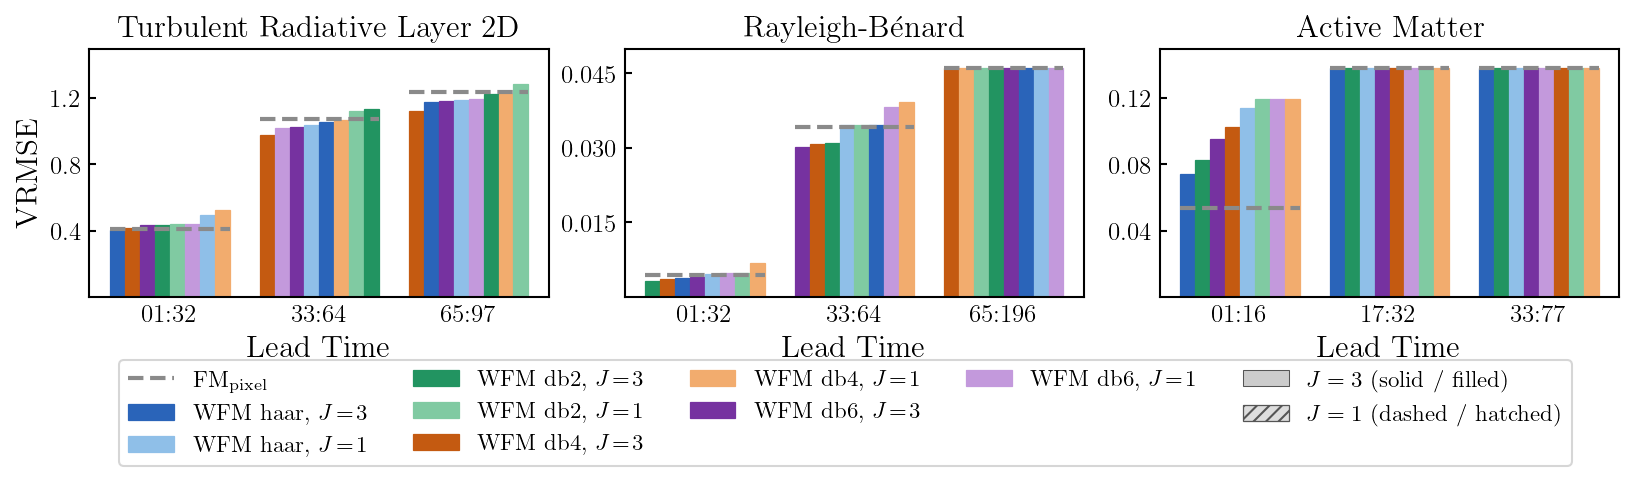

In [7]:
pde_bar_ylims_vrmse = {
    'turbulent_radiative_layer_2D': (0, 1.5),
    'rayleigh_benard':              (0, 0.05),
    'active_matter':                (0, 0.15),
}

# ── Figure A: VRMSE — deterministic models ────────────────────────────────────
fig_vrmse = make_bar_fig(
    stats_df,
    model_subset  = det_models + ours_models + [gen_models[-1]],
    metric_col    = "crps",
    metric_label  = "VRMSE",
    pde_ylims     = pde_bar_ylims_vrmse,
    PDEs          = PDEs,
    PDE_LABELS    = PDE_LABELS,
    ncol_legend   = 5,
    legend_pos    = (0.5, -0.15),
)
#fig_vrmse.savefig(f"{PROJECT_ROOT}/figures/ABLATION_vrmse_wavelets.pdf", dpi=400, bbox_inches="tight", transparent=False)
plt.show()

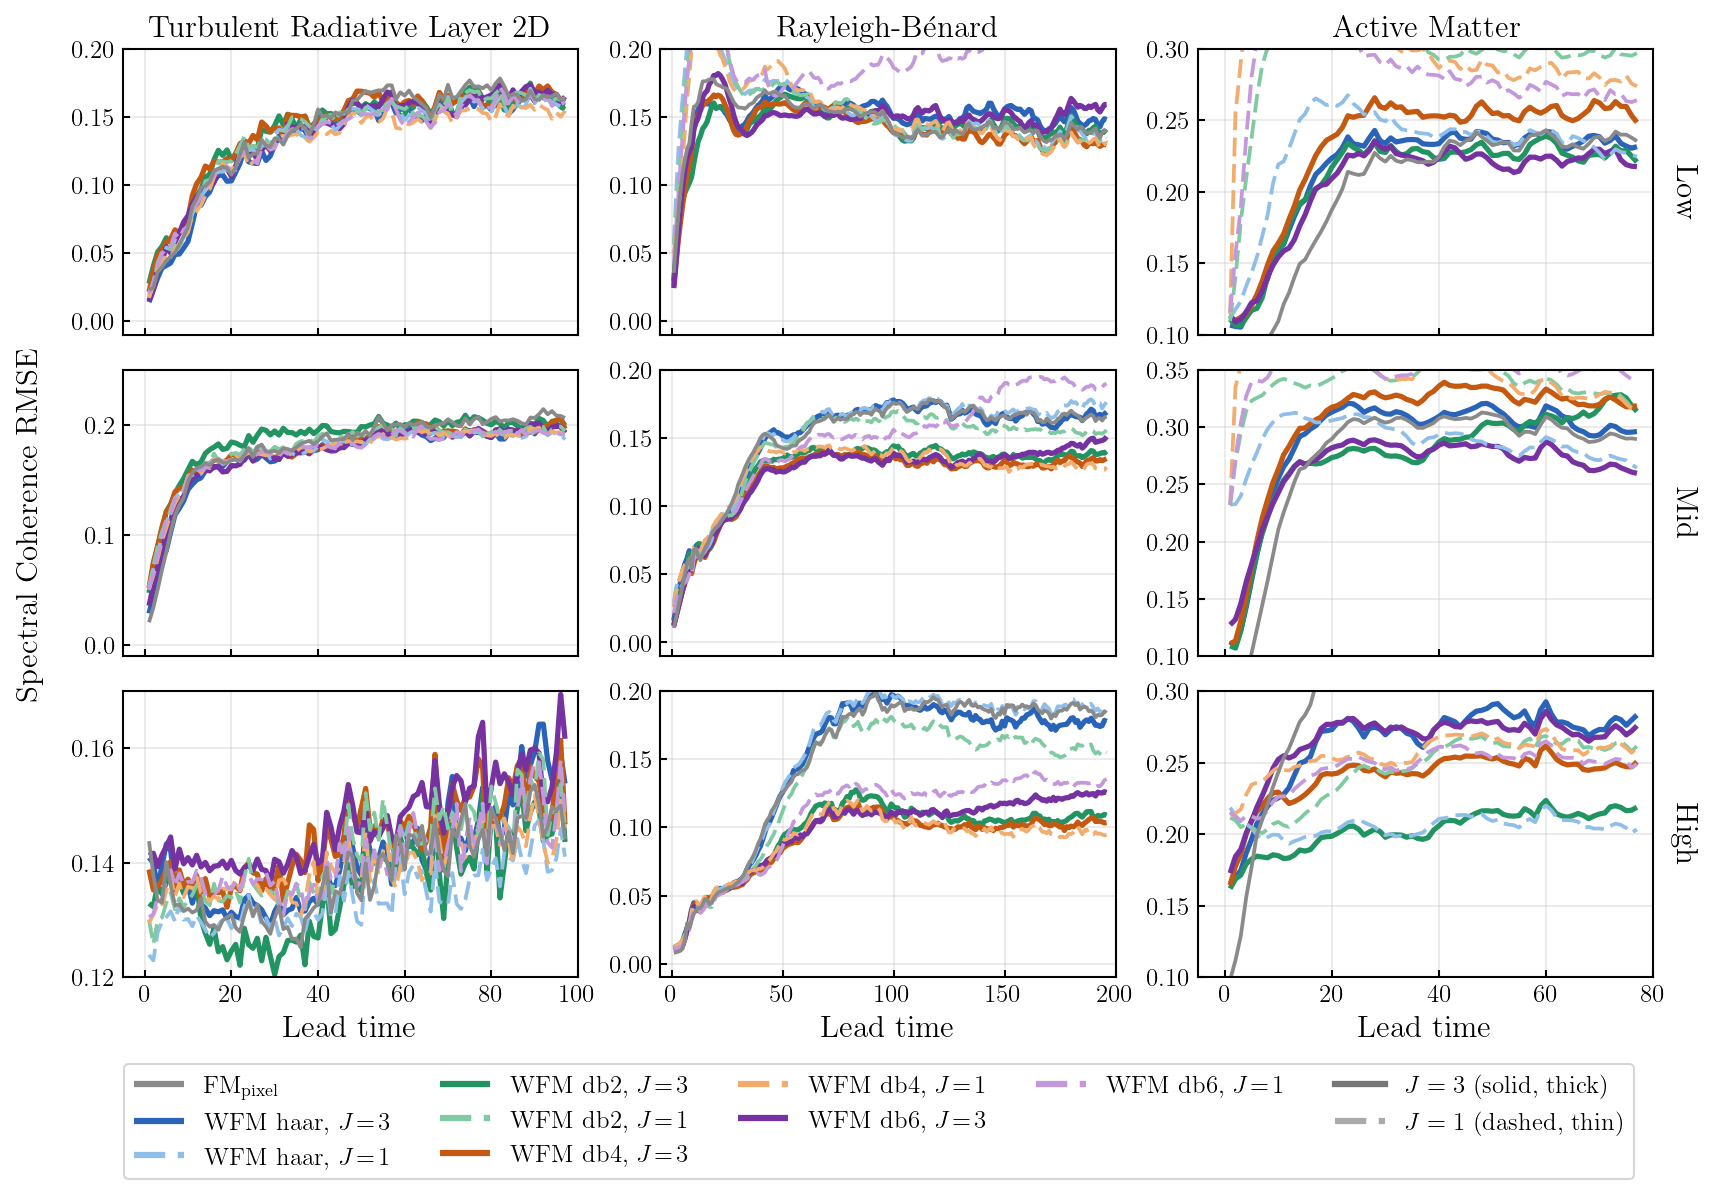

In [8]:
band_ylims = {
    "turbulent_radiative_layer_2D": {
        "Low":  (-0.01, 0.2),
        "Mid":  (-0.01, 0.25),
        "High": (0.12, 0.17),
    },
    "rayleigh_benard": {
        "Low":  (-0.01, 0.20),
        "Mid":  (-0.01, 0.20),
        "High": (-0.01, 0.20),
    },
    "active_matter": {
        "Low":  (0.1, 0.30),
        "Mid":  (0.1, 0.35),
        "High": (0.1, 0.30),
    },
}
DEFAULT_YLIM = (-0.01, 0.35)

color_to_model = {v: k for k, v in palette.items()}

n_pdes, n_bands = len(PDEs), len(bands)
fig1, axs1 = plt.subplots(
    n_bands, n_pdes,
    figsize=(TEXT_WIDTH, ROW_HEIGHT * n_bands),
    sharex="col",
    sharey=False,
)

raw_h, raw_l = None, None
for col, pde in enumerate(PDEs):
    table = stats_df[(stats_df["pde"] == pde) & (stats_df["model"].isin(det_models + gen_models))]
    for row, band in enumerate(bands):
        ax = axs1[row, col]
        sns.lineplot(
            table, x="step",
            y=f"rmse_c_{band.lower()}",
            hue="model", style="model",
            dashes=dashes,
            estimator=aggregate, errorbar=None,
            palette=palette, ax=ax, linewidth=1.0,
            alpha=1.0,
        )
        for line in ax.get_lines():
            hex_color = mcolors.to_hex(line.get_color())
            model = color_to_model.get(hex_color)
            if model and model in linewidths:
                line.set_linewidth(linewidths[model])
        if raw_h is None:
            raw_h, raw_l = ax.get_legend_handles_labels()
        ax.get_legend().remove()
        ax.grid(alpha=0.3)
        ax.tick_params(direction="in", which="both", labelsize=12)
        ax.set_xlim(*pde_xlims[pde])
        ylim = band_ylims.get(pde, {}).get(band, DEFAULT_YLIM)
        ax.set_ylim(*ylim)
        ax.set_xlabel("Lead time" if row == n_bands - 1 else "", fontsize=15)
        ax.set_ylabel("", fontsize=15)
        ax.tick_params(labelleft=True, labelsize=12)
        if row == 0:
            ax.set_title(PDE_LABELS.get(pde, pde), fontsize=15, fontweight="bold")

fig1.supylabel("Spectral Coherence RMSE", fontsize=15, x=0.02, y=0.58)

raw_name_to_handle = dict(zip(raw_l, raw_h))
ordered_models     = legend_order(list(raw_name_to_handle.keys()))
ordered_handles    = [raw_name_to_handle[m] for m in ordered_models]
ordered_labels     = [labels.get(m, m)      for m in ordered_models]

# ── Scale-key ─────────────────────────────────────────────────────────────────
sep = mlines.Line2D([], [], visible=False, label="")
sk3 = mlines.Line2D([], [], color="#777777", linewidth=2.5, linestyle="-",
                    label=r"$J=3$ (solid, thick)")
sk1 = mlines.Line2D([], [], color="#aaaaaa", linewidth=1.8, linestyle=(0,(5,2)),
                    label=r"$J=1$ (dashed, thin)")

fig1.tight_layout(pad=0.8)
fig1.subplots_adjust(bottom=0.22, left=0.08, right=0.93)

for row, band in enumerate(bands):
    ax = axs1[row, -1]
    bb = ax.get_position()
    fig1.text(
        0.94, (bb.y0 + bb.y1) / 2, band,
        ha="left", va="center",
        rotation=-90, fontsize=15,
        transform=fig1.transFigure,
    )

legend = fig1.legend(
    ordered_handles + [sep, sk3, sk1],
    ordered_labels  + ["", r"$J=3$ (solid, thick)", r"$J=1$ (dashed, thin)"],
    loc="lower center", ncol=5,
    bbox_to_anchor=(0.5, 0.05),
    frameon=True, fontsize=12,
)
for handle in legend.legend_handles:
    if hasattr(handle, "set_linewidth"):
        handle.set_linewidth(3.0)

plt.show()


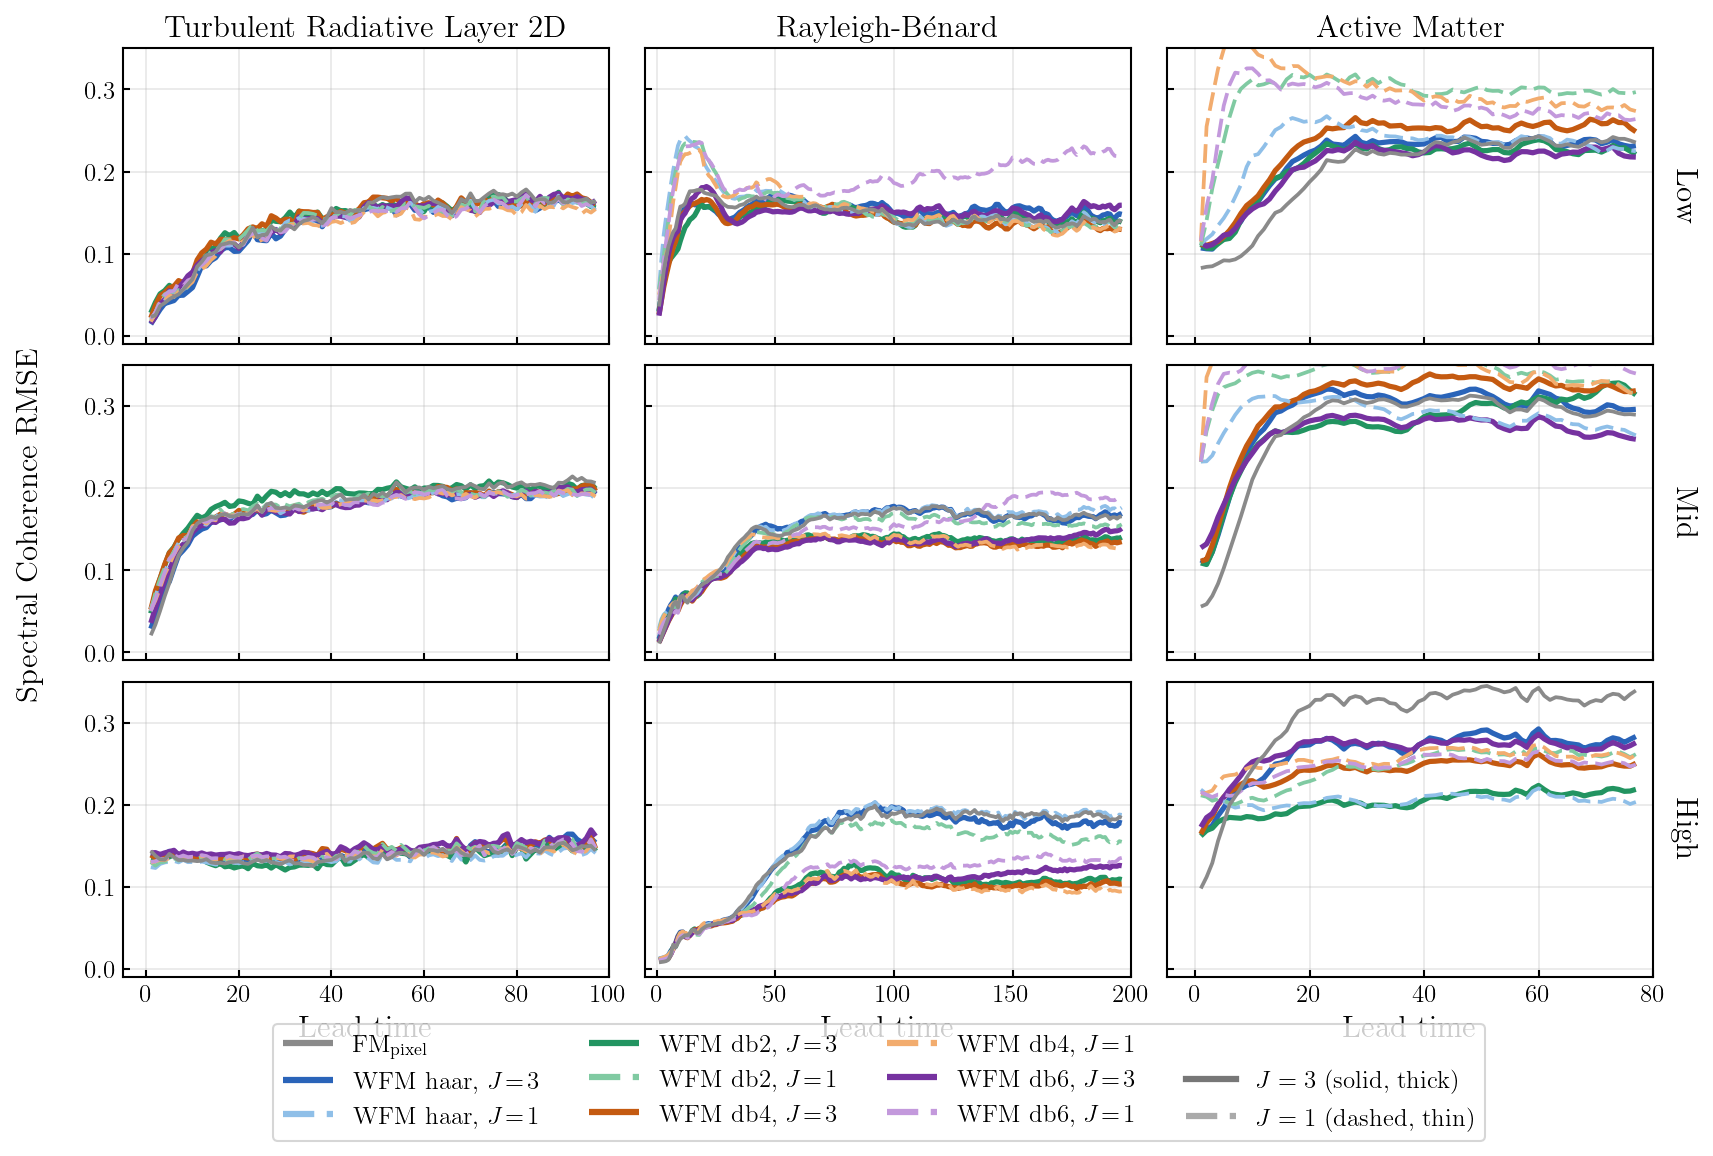

In [9]:
band_ylims = {
    "Low":  (-0.01, 0.35),
    "Mid":  (-0.01, 0.35),
    "High": (-0.01, 0.35),
}

color_to_model = {v: k for k, v in palette.items()}

n_pdes, n_bands = len(PDEs), len(bands)
fig1, axs1 = plt.subplots(
    n_bands, n_pdes,
    figsize=(TEXT_WIDTH, ROW_HEIGHT * n_bands),
    sharex="col",
    sharey="row",
)

raw_h, raw_l = None, None

for col, pde in enumerate(PDEs):
    table = stats_df[(stats_df["pde"] == pde) & (stats_df["model"].isin(det_models + gen_models))]
    for row, band in enumerate(bands):
        ax = axs1[row, col]
        sns.lineplot(
            table, x="step",
            y=f"rmse_c_{band.lower()}",
            hue="model", style="model",
            dashes=dashes,
            estimator=aggregate, errorbar=None,
            palette=palette, ax=ax, linewidth=1.0,
            alpha=1.0,
        )
        for line in ax.get_lines():
            hex_color = mcolors.to_hex(line.get_color())
            model = color_to_model.get(hex_color)
            if model and model in linewidths:
                line.set_linewidth(linewidths[model])
        if raw_h is None:
            raw_h, raw_l = ax.get_legend_handles_labels()
        ax.get_legend().remove()
        ax.grid(alpha=0.3)
        ax.tick_params(direction="in", which="both", labelsize=12)
        ax.set_xlim(*pde_xlims[pde])
        ax.set_ylim(*band_ylims[band])
        ax.set_xlabel("Lead time" if row == n_bands - 1 else "", fontsize=15)
        ax.set_ylabel("", fontsize=15)
        if col > 0:
            ax.tick_params(labelleft=False, labelsize=12)
        if row == 0:
            ax.set_title(PDE_LABELS.get(pde, pde), fontsize=15, fontweight="bold")

fig1.supylabel("Spectral Coherence RMSE", fontsize=15, x=0.02, y=0.58)

raw_name_to_handle = dict(zip(raw_l, raw_h))
ordered_models     = legend_order(list(raw_name_to_handle.keys()))
ordered_handles    = [raw_name_to_handle[m] for m in ordered_models]
ordered_labels     = [labels.get(m, m)      for m in ordered_models]

# ── Scale-key ─────────────────────────────────────────────────────────────────
sep = mlines.Line2D([], [], visible=False, label="")
sk3 = mlines.Line2D([], [], color="#777777", linewidth=2.5, linestyle="-",
                    label=r"$J=3$ (solid, thick)")
sk1 = mlines.Line2D([], [], color="#aaaaaa", linewidth=1.8, linestyle=(0,(5,2)),
                    label=r"$J=1$ (dashed, thin)")

fig1.tight_layout(pad=0.8)
fig1.subplots_adjust(bottom=0.22, left=0.08, right=0.93)

for row, band in enumerate(bands):
    ax = axs1[row, -1]
    bb = ax.get_position()
    fig1.text(
        0.94, (bb.y0 + bb.y1) / 2, band,
        ha="left", va="center",
        rotation=-90, fontsize=15,
        transform=fig1.transFigure,
    )

legend = fig1.legend(
    ordered_handles + [sep, sk3, sk1],
    ordered_labels  + ["", r"$J=3$ (solid, thick)", r"$J=1$ (dashed, thin)"],
    loc="lower center", ncol=4,
    bbox_to_anchor=(0.5, 0.08),
    frameon=True, fontsize=12,
)
for handle in legend.legend_handles:
    if hasattr(handle, "set_linewidth"):
        handle.set_linewidth(3.0)

#plt.savefig(f"{PROJECT_ROOT}/figures/ABLATION_spectral_coherence_rmse_wavelets.pdf", dpi=400, bbox_inches="tight", transparent=False)
plt.show()


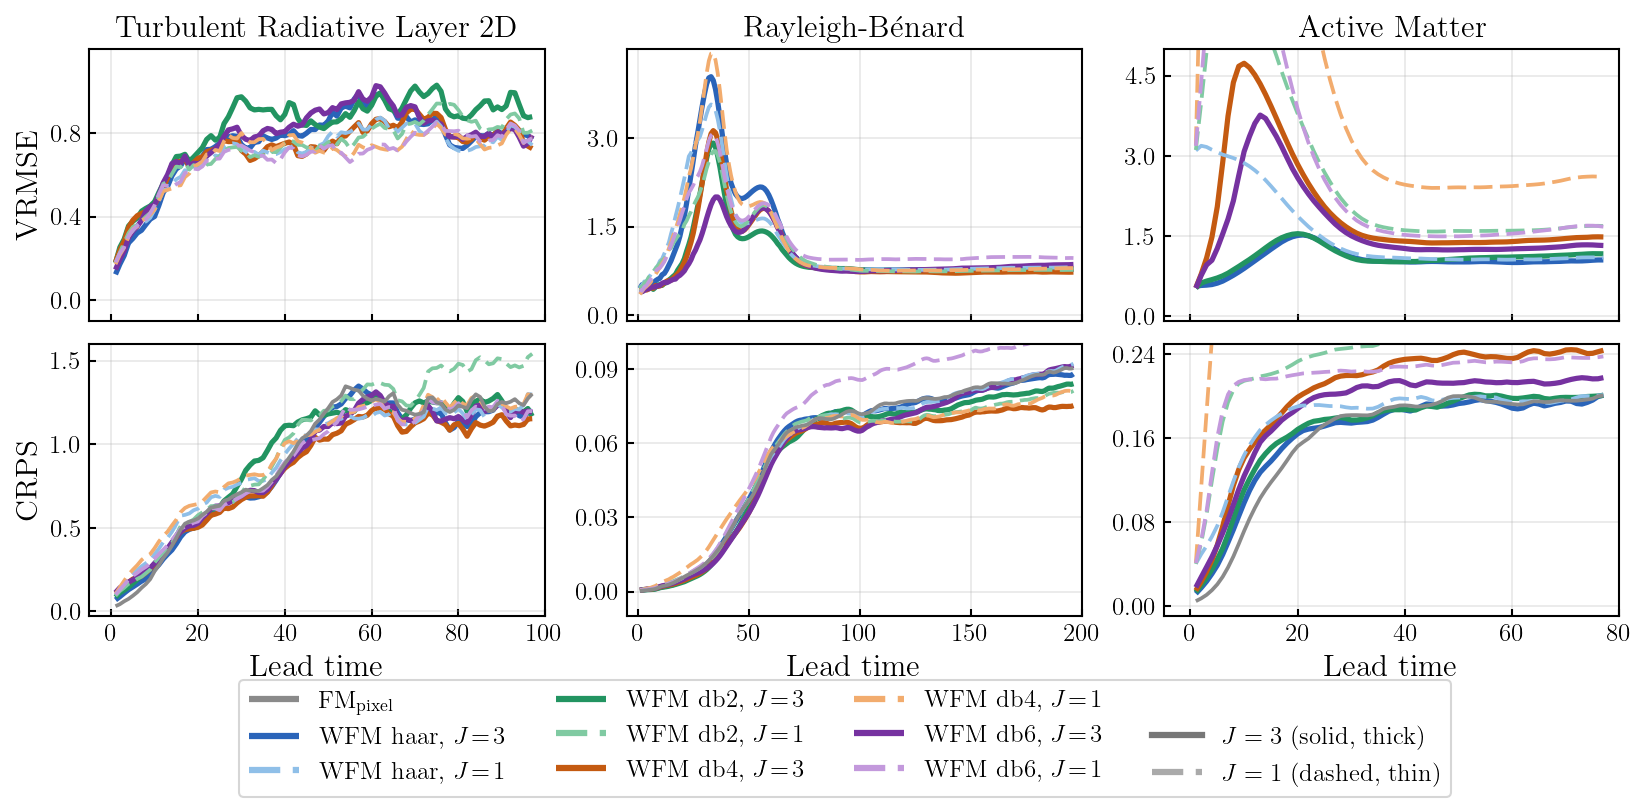

In [10]:
n_pdes = 3

color_to_model = {v: k for k, v in palette.items()}

# Per-metric model filter
metric_models = {
    "VRMSE": [m for m in MODEL_REGISTRY if {"deterministic", "ours"} & set(MODEL_REGISTRY[m]["groups"])],
    "CRPS" : [m for m in MODEL_REGISTRY if "generative" in MODEL_REGISTRY[m]["groups"]],
}

pde_metric_ylims = {
    'turbulent_radiative_layer_2D': {
        "VRMSE": (-0.1, 1.2),
        "CRPS":  (-0.03, 1.6),
    },
    'rayleigh_benard': {
        "VRMSE": (-0.1, 4.5),
        "CRPS":  (-0.01, 0.10),
    },
    'active_matter': {
        "VRMSE": (-0.1, 5.0),
        "CRPS":  (-0.01, 0.25),
    },
}

metrics     = ["VRMSE", "CRPS"]
metric_cols = {"VRMSE": "vrmse", "CRPS": "crps"}
n_metrics   = len(metrics)

fig2, axs2 = plt.subplots(
    n_metrics, n_pdes,
    figsize=(TEXT_WIDTH, ROW_HEIGHT * n_metrics),
    sharex="col",
    sharey=False,
)

raw_h, raw_l = None, None
all_key_to_handle = {}

for col, pde in enumerate(PDEs):
    for row, metric in enumerate(metrics):
        ax = axs2[row, col]

        table = stats_df[
            (stats_df["pde"]   == pde) &
            (stats_df["model"].isin(metric_models[metric]))
        ]

        sns.lineplot(
            table, x="step", y=metric_cols[metric],
            hue="model", style="model",
            dashes=dashes, estimator=aggregate, errorbar=None,
            palette=palette, ax=ax, linewidth=1.0,
            alpha=1.0,
        )

        for line in ax.get_lines():
            hex_color = mcolors.to_hex(line.get_color())
            model = color_to_model.get(hex_color)
            if model and model in linewidths:
                line.set_linewidth(linewidths[model])

        h, l = ax.get_legend_handles_labels()
        for key, handle in zip(l, h):
            if key not in all_key_to_handle:
                all_key_to_handle[key] = handle

        ax.get_legend().remove()
        ax.grid(alpha=0.3)
        ax.tick_params(direction="in", which="both", labelsize=12)
        ax.set_xlim(*pde_xlims[pde])
        ylo, yhi = pde_metric_ylims[pde][metric]
        ax.set_ylim(ylo, yhi)
        ax.yaxis.set_major_locator(MaxNLocator(nbins=4, prune="both"))
        ax.set_xlabel("Lead time" if row == n_metrics - 1 else "", fontsize=15)
        if col == 0:
            ax.set_ylabel(metric, fontsize=15)
        else:
            ax.set_ylabel("")
        ax.tick_params(labelleft=True, labelsize=12)
        if row == 0:
            ax.set_title(PDE_LABELS.get(pde, pde), fontsize=15, fontweight="bold")

fig2.align_labels()
fig2.tight_layout(pad=0.8)
fig2.subplots_adjust(bottom=0.26, left=0.08, right=0.93)

ordered_keys    = legend_order(list(all_key_to_handle.keys()))
ordered_handles = [all_key_to_handle[k] for k in ordered_keys]
ordered_labels  = [labels.get(k, k)     for k in ordered_keys]

# ── Scale-key annotation ──────────────────────────────────────────────────────
sep = mlines.Line2D([], [], visible=False, label="")
sk3 = mlines.Line2D([], [], color="#777777", linewidth=2.5, linestyle="-",
                    label=r"$J=3$ (solid, thick)")
sk1 = mlines.Line2D([], [], color="#aaaaaa", linewidth=1.8, linestyle=(0,(5,2)),
                    label=r"$J=1$ (dashed, thin)")

legend = fig2.legend(
    ordered_handles + [sep, sk3, sk1],
    ordered_labels  + ["", r"$J=3$ (solid, thick)", r"$J=1$ (dashed, thin)"],
    loc="lower center", ncol=4,
    bbox_to_anchor=(0.5, 0.03),
    frameon=True, fontsize=12,
)
for handle in legend.legend_handles:
    if hasattr(handle, "set_linewidth"):
        handle.set_linewidth(3.0)

#plt.savefig(f"{PROJECT_ROOT}/figures/ABLATION_spectral_vrmse_crps_wavelets.pdf", dpi=400, bbox_inches="tight", transparent=False)
plt.show()
